In [1]:
import matplotlib.pyplot as plt
import torch

from pi_solvers import sde_lib, solver_lib, utils

torch.manual_seed(42)

In [2]:
model, encoder = utils.load_edm_checkpoint("https://nvlabs-fi-cdn.nvidia.com/edm/pretrained/edm-ffhq-64x64-uncond-ve.pkl")
model = model.to("cuda")

In [3]:
x = torch.zeros((16, model.img_channels, model.img_resolution, model.img_resolution)).to("cuda")
t = torch.ones((1,)).to("cuda")
noise = torch.randn_like(x) * 80

In [4]:
if model.label_dim:
    labels = torch.eye(model.label_dim, device="cuda")[torch.randint(high=model.label_dim, size=(16,), device="cuda")]
else:
    labels = None

In [42]:
sigma_min = 0.002
sigma_max = 80

sde_ = sde_lib.EDMSDE(ode=False).to("cuda")
rsde = sde_.get_reverse_sde(model, ode_threshold=0.0).to("cuda")
# rsde = sde_lib.construct_churn_sde(model, 50, S_churn=40, S_max=100).to("cuda")

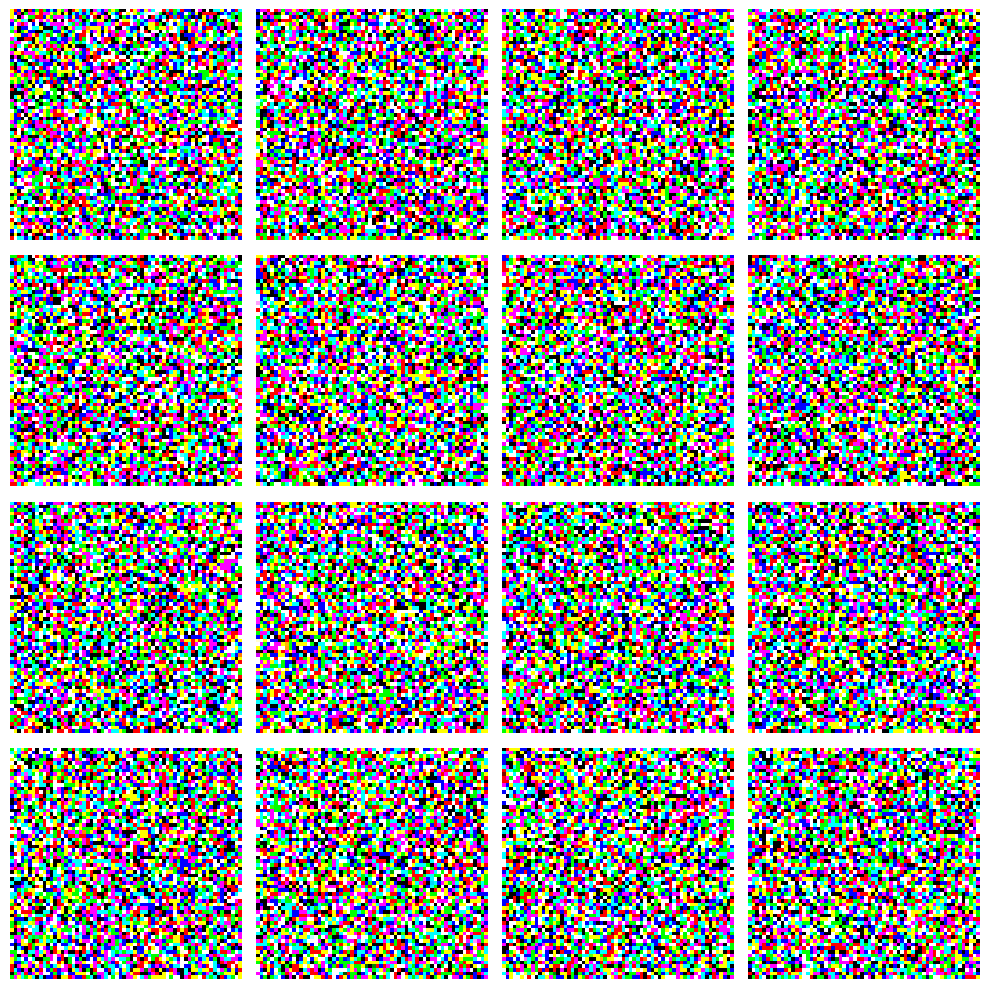

In [43]:
images = encoder.decode(noise).permute(0, 2, 3, 1)

def plot_images(images):
    fig, axes = plt.subplots(4, 4)
    fig.set_size_inches(10, 10)
    
    for i in range(4):
        for j in range(4):
            axes[i][j].imshow(images[i * 4 + j])
            axes[i][j].axis("off")
            
    fig.tight_layout()
    
plot_images(images.cpu())

In [44]:
n_steps = 50
rho = 7
# From EDM2 code
discretisation = solver_lib.get_edm_schedule(n_steps, sigma_min, sigma_max, rho)
# discretisation = solver_lib.get_entropy_schedule(n_steps, entropy_checkpoint="../refs/ret_ffhq.pt")
# discretisation = solver_lib.get_pi_schedule(50, 0, "../data/image_testing/pi_2/75NFE_2/data/_t.csv")

In [45]:
discretisation

tensor([8.0000e+01, 7.1501e+01, 6.3788e+01, 5.6799e+01, 5.0478e+01, 4.4769e+01,
        3.9623e+01, 3.4992e+01, 3.0833e+01, 2.7106e+01, 2.3771e+01, 2.0795e+01,
        1.8143e+01, 1.5787e+01, 1.3699e+01, 1.1851e+01, 1.0222e+01, 8.7882e+00,
        7.5306e+00, 6.4305e+00, 5.4711e+00, 4.6371e+00, 3.9145e+00, 3.2907e+00,
        2.7541e+00, 2.2943e+00, 1.9020e+00, 1.5686e+00, 1.2866e+00, 1.0492e+00,
        8.5045e-01, 6.8486e-01, 5.4770e-01, 4.3480e-01, 3.4247e-01, 2.6748e-01,
        2.0702e-01, 1.5868e-01, 1.2036e-01, 9.0259e-02, 6.6856e-02, 4.8860e-02,
        3.5187e-02, 2.4934e-02, 1.7356e-02, 1.1845e-02, 7.9070e-03, 5.1493e-03,
        3.2608e-03, 2.0000e-03, 0.0000e+00])

In [40]:
rsde.reset()

em_solver = solver_lib.HeunSolver(rsde, discretisation).to("cuda")

x_em = em_solver.solve(noise.clone(), labels)

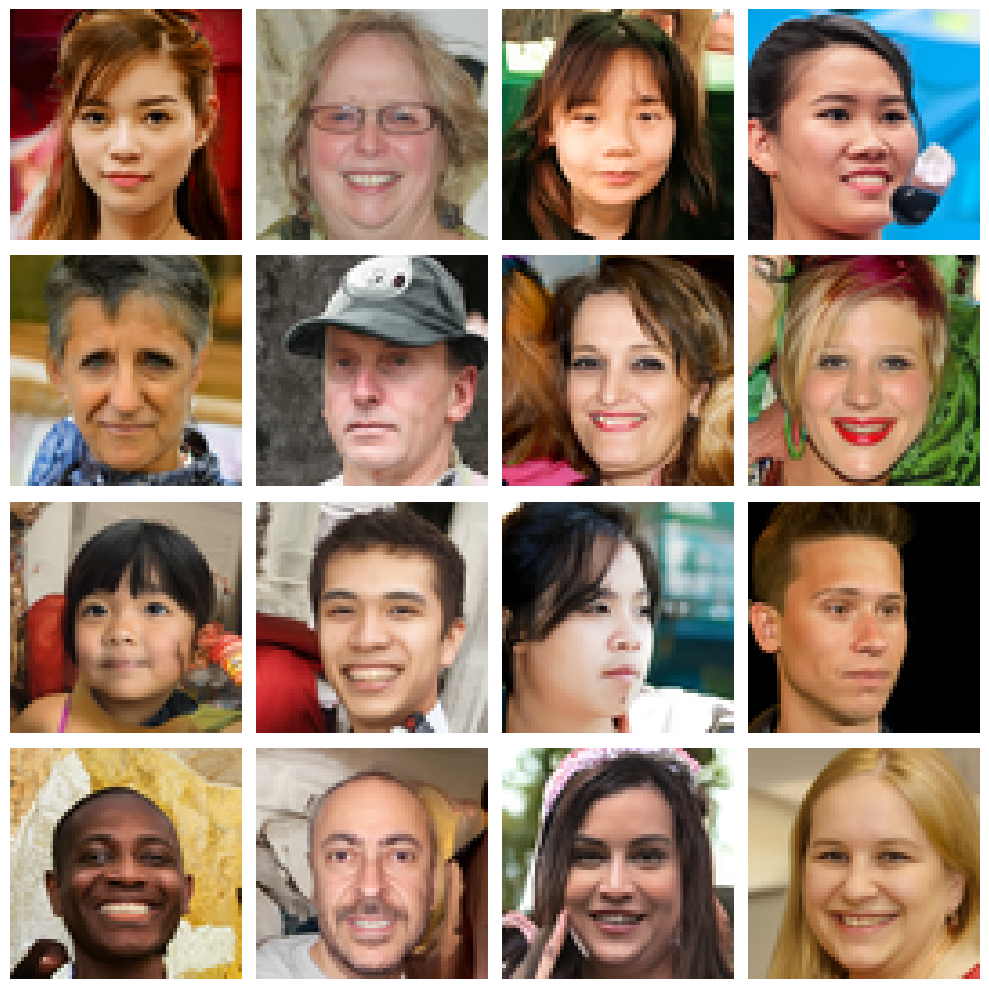

In [41]:
images = encoder.decode(x_em).permute(0, 2, 3, 1)

plot_images(images.cpu())

In [36]:
rsde.nfe / 16

99.0

In [9]:
sigmas = []
sigmas_std = []
trajectories = []
hs = []

def pi_callback(x, t, h, error):    
    print(f"sigma = {torch.mean(t)}", end=" ")
    print(f"h = {torch.mean(h)}", end=" ")
    print(f"error = {torch.mean(error)}")
    sigmas.append(torch.mean(t).cpu())
    hs.append(torch.mean(h).cpu())
    sigmas_std.append(torch.std(t).cpu())
    trajectories.append(t[0:2].clone())

In [58]:
sigmas = [80]
sigmas_std = [0]
trajectories = []
hs = []

rsde.reset()

pi_solver = solver_lib.construct_heun_end_adaptive_solver(
    solver_lib.PISolver,
    rsde,
    ode_threshold=0.0,
    n_ode_steps=0,
    ki=0.3,
    kp=0.1,
    tau_a=0.005,
    tau_r=1.15,
    alpha=0.9,
    h_start=40,
    max_decrease=0.2,
    max_increase=5,
    interval=(80, 0.),
    abs_error=False,
    batch_norm=False
).to("cuda")

x_pi = pi_solver.solve(noise.clone(), labels, callback=pi_callback)

sigma = 40.0 h = -14.944235801696777 error = 10.549083709716797
sigma = 25.055763244628906 h = -9.292839050292969 error = 5.461374759674072
sigma = 15.762924194335938 h = -5.485530376434326 error = 5.2765021324157715
sigma = 10.277395248413086 h = -3.412867784500122 error = 4.5872039794921875
sigma = 6.864526748657227 h = -2.179053783416748 error = 4.15164852142334
sigma = 4.6854729652404785 h = -1.4277610778808594 error = 3.795534133911133
sigma = 3.257711887359619 h = -0.9586721658706665 error = 3.491252899169922
sigma = 2.299039840698242 h = -0.6567049026489258 error = 3.2522716522216797
sigma = 1.6423349380493164 h = -0.45823192596435547 error = 3.051239490509033
sigma = 1.184103012084961 h = -0.32466599345207214 error = 2.8903534412384033
sigma = 0.8594370484352112 h = -0.23238790035247803 error = 2.779757022857666
sigma = 0.6270490884780884 h = -0.1685216724872589 error = 2.6644182205200195
sigma = 0.45852744579315186 h = -0.12332859635353088 error = 2.5768280029296875
sigma = 0.

Text(0, 0.5, '$\\pi_{\\alpha}(\\log \\sigma_i)$')

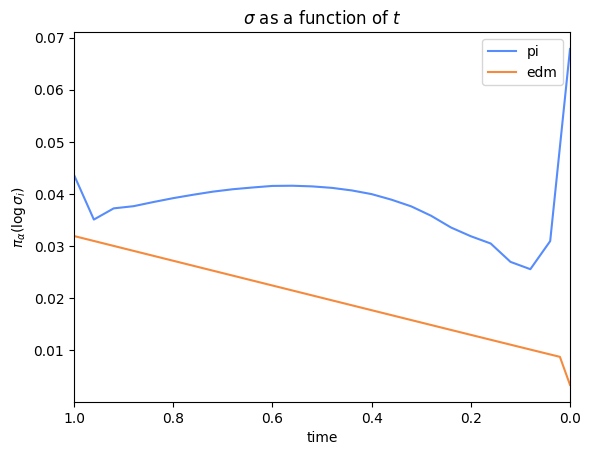

In [59]:
pi = (torch.tensor(sigmas[:-2]) / torch.abs(torch.tensor(hs[:-1]))) / (rsde.nfe / 8)
pi = pi / torch.sum(pi)
edm_pi = discretisation[:-1] / (discretisation[:-1] - discretisation[1:]) / (n_steps)
edm_pi = edm_pi / torch.sum(edm_pi)

plt.title(r"$\sigma$ as a function of $t$")
plt.plot(torch.linspace(1, 0, len(pi)), pi, label="pi")
plt.plot(torch.linspace(1, 0, len(edm_pi)), edm_pi.cpu(), label="edm")

plt.legend()
plt.xlim(1, 0)
plt.xlabel("time")
plt.ylabel(r"$\pi_{\alpha}(\log \sigma_i)$")

In [60]:
rsde.nfe / 16

50.0

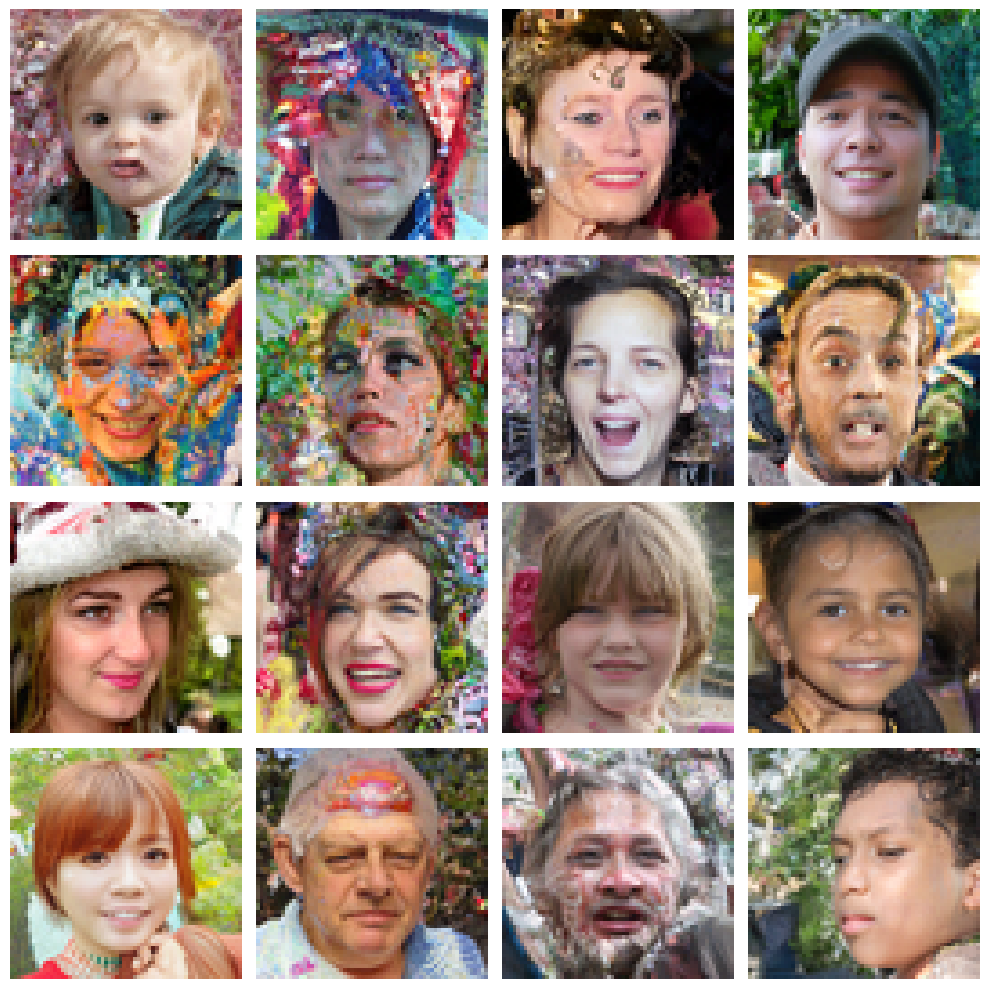

In [61]:
images = encoder.decode(x_pi).permute(0, 2, 3, 1)
plot_images(images.cpu())

In [95]:
sigmas = [80]
sigmas_std = [0]
trajectories = []

rsde.reset()

ggf_solver = solver_lib.construct_heun_end_adaptive_solver(
    solver_lib.GottaGoFast,
    rsde,
    ode_threshold=0.0,
    n_ode_steps=0,
    tau_a=0.0078,   # Range is -1, 1, which is mentioned in paper to correspond to a tau_a of (1 -- 1 / 256 = 0.0078)
    tau_r=22.5,
    h_start=25,
    r=0.1,
    alpha=0.7,
    interval=(80, 0.0)
).to("cuda")

x_ggf = ggf_solver.solve(noise.clone(), labels, pi_callback)

sigma = 55.0 h = -19.088153839111328 error = 0.4195191562175751
sigma = 37.10652160644531 h = -13.708194732666016 error = 0.7936636209487915
sigma = 31.947797775268555 h = -9.328346252441406 error = 1.827125072479248
sigma = 27.440380096435547 h = -6.644136428833008 error = 1.402660846710205
sigma = 20.796239852905273 h = -5.210058689117432 error = 0.39347511529922485
sigma = 15.586183547973633 h = -4.1211724281311035 error = 0.36231857538223267
sigma = 12.000612258911133 h = -3.1242053508758545 error = 2.153127670288086
sigma = 9.377298355102539 h = -2.415188789367676 error = 0.6428829431533813
sigma = 6.9621100425720215 h = -1.8944604396820068 error = 0.48772993683815
sigma = 5.6392598152160645 h = -1.4551646709442139 error = 0.8439783453941345
sigma = 4.246402740478516 h = -1.1322500705718994 error = 0.48382335901260376
sigma = 3.166473388671875 h = -0.8739534616470337 error = 0.5210486650466919
sigma = 2.4112956523895264 h = -0.6659896969795227 error = 0.7383538484573364
sigma = 1.

In [96]:
rsde.nfe / 16

49.75

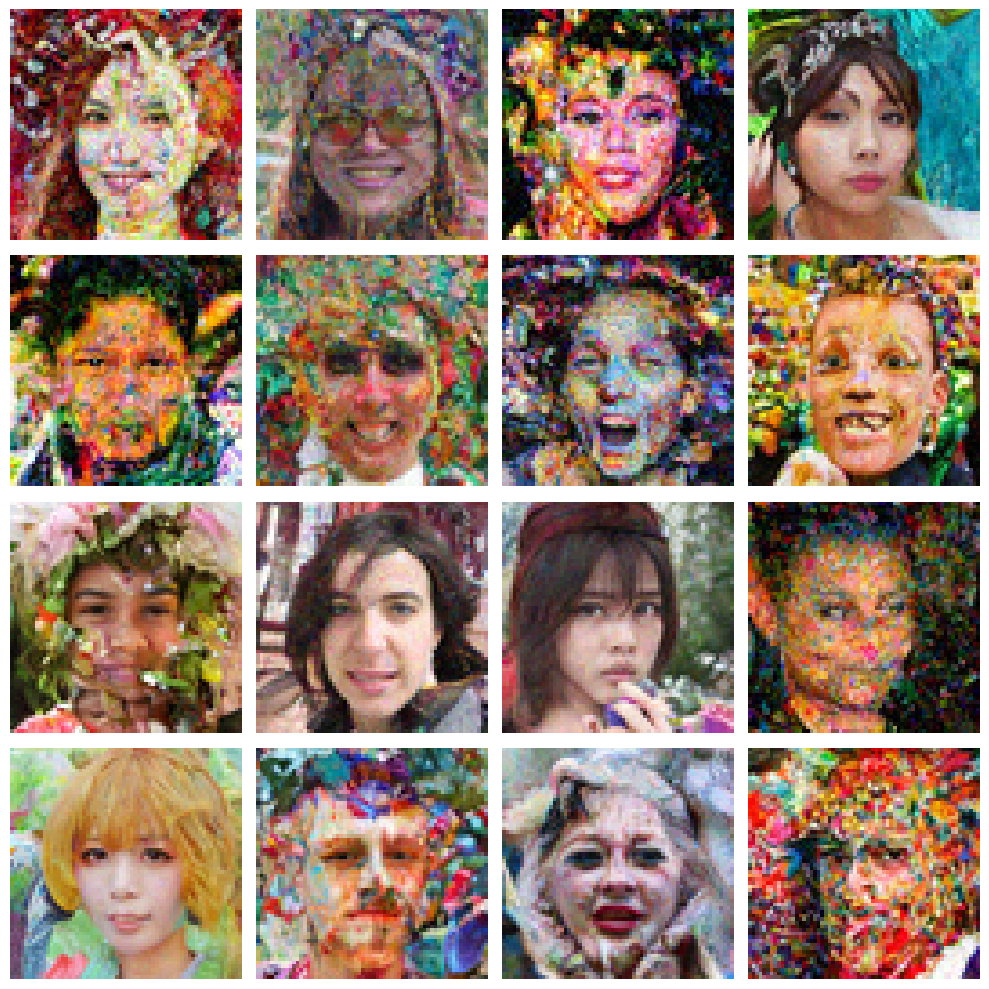

In [97]:
images = encoder.decode(x_ggf).permute(0, 2, 3, 1)
plot_images(images.cpu())

In [62]:
edm_schedule = solver_lib.get_edm_schedule(100)

In [63]:
trajectory_1 = []
trajectory_2 = []
for element in trajectories:
    trajectory_1.append(element[0, 0, 0].cpu())
    trajectory_2.append(element[1, 0, 0].cpu())

trajectory_1 = torch.cat([torch.tensor([80]), torch.cat(trajectory_1)])
trajectory_2 = torch.cat([torch.tensor([80]), torch.cat(trajectory_2)])

trajectory_1 = trajectory_1[trajectory_1 > 0.05]
trajectory_2 = trajectory_2[trajectory_2 > 0.05]
discretisation = discretisation[discretisation > 0.05]
edm_schedule = edm_schedule[edm_schedule > 0.05]

NameError: name 'sigmas' is not defined

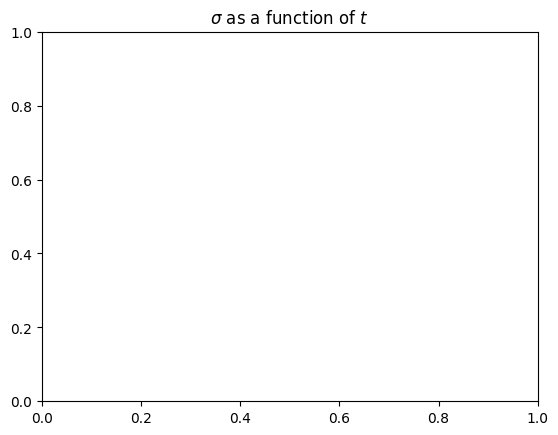

In [13]:
plt.title(r"$\sigma$ as a function of $t$")
# plt.plot(torch.linspace(1, 0, len(trajectory_1)), trajectory_1.cpu(), label="ggf trajectory")
# plt.plot(torch.linspace(1, 0, len(trajectory_2)), trajectory_2.cpu(), label="ggf trajectory")

plt.plot(torch.linspace(1, 0, len(sigmas)), torch.tensor(sigmas))
plt.plot(torch.linspace(1, 0, len(discretisation)), discretisation, label="pi-average")
# plt.plot(torch.linspace(1, 0, len(edm_schedule)), edm_schedule, label="edm")

plt.legend()
plt.xlim(1, 0)
plt.xlabel("time")
plt.ylabel("sigma")
plt.yscale("log")

In [17]:
edm_solver = solver_lib.EDMSolver(rsde, discretisation, model,S_churn=40, S_min=0.05, S_max=50, S_noise=1.003).to("cuda")
x_edm = edm_solver.solve(noise.clone(), labels)

In [18]:
print(rsde.nfe / 16)
rsde.reset()

75.375


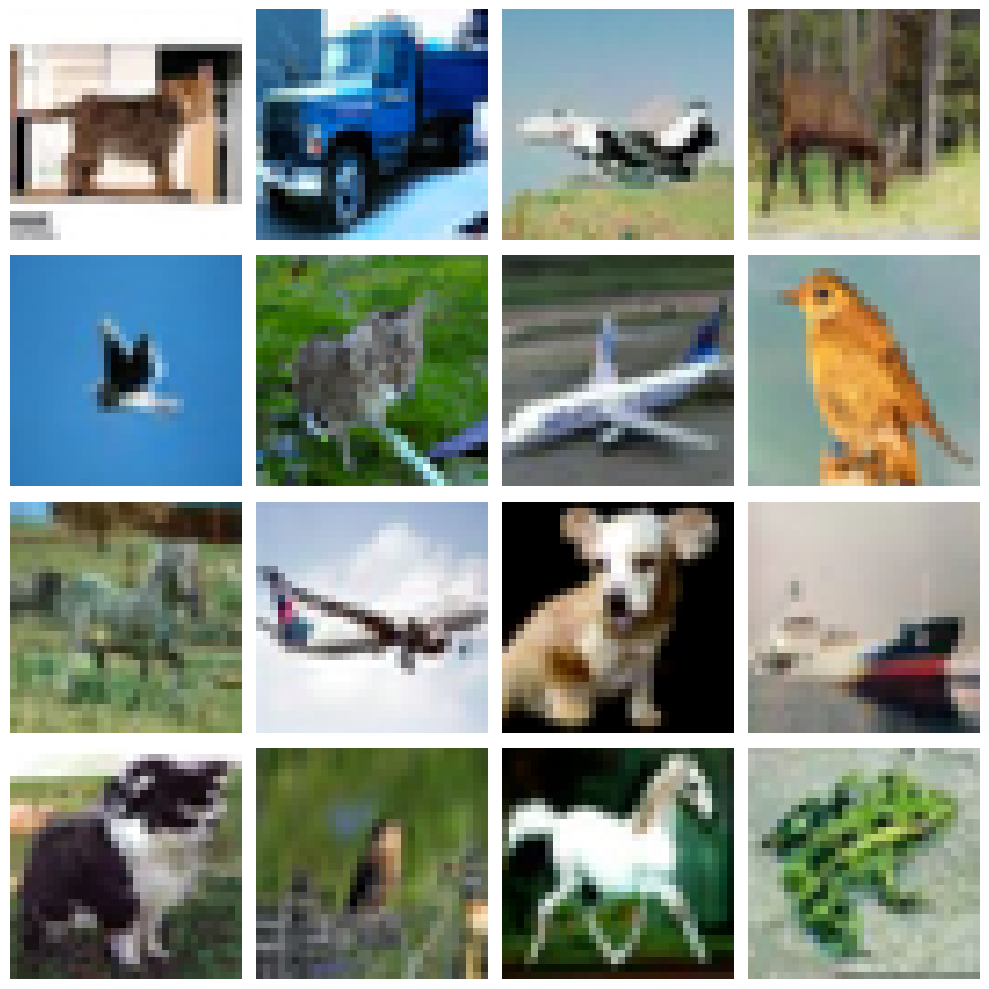

In [19]:
images = encoder.decode(x_edm).permute(0, 2, 3, 1)
plot_images(images.cpu())